# Velocity-only p(v | R) versus joint p(x, y, v): does modelling the positions change the posterior?

## The question

The production NLE conditions on the projected radius and models only the
velocity,

$$\mathcal L_{\rm los}(\theta) = \prod_i p(v_i \mid \log R_i,\, \theta,\,
\log r_{1/2},\, \sigma_i).$$

The alternative (`condition_on_position = False`) models the sky position too:

$$\mathcal L_{\rm joint}(\theta) = \prod_i p(x_i, y_i, v_i \mid \theta,\,
\log r_{1/2},\, \sigma_i).$$

With $r_{1/2}$ fixed at its photometric value, the joint density factorises
exactly as $p(v \mid R, \theta, r_{1/2})\, p(x, y \mid r_{1/2})$, and the
second factor is the projected Plummer profile, which carries **no**
$\theta$. So $\log\mathcal L_{\rm joint} = \log\mathcal L_{\rm los} +
{\rm const}$ and the two posteriors are identical *if both flows are exact*.
A position-only selection function multiplies the velocity-only likelihood by
a $\theta$-independent factor as well, which is the Jeans-style argument for
conditioning on $R$ in the first place.

What can differ is the approximation. The joint flow has to *learn* that its
position marginal does not depend on $\theta$; nothing in the training
objective enforces it. Any residual dependence is a per-star error that is
coherent across a galaxy's stars, so $\epsilon$ nats per star becomes
$N\epsilon$ nats in the galaxy likelihood. This notebook:

1. builds both galaxy likelihoods on a Draco mock,
2. scans and samples them,
3. measures the "leak" $\log\mathcal L_{\rm joint} - \log\mathcal L_{\rm
   los}$ over the posterior, which is a constant for an exact position factor,
4. shows the batch result on all twelve mocks with and without the Walker
   2023 selection.

**Models.** Both on shards 0–1, T2 architecture, 30k steps: the velocity-only
model `errtest_noisy` (run `6xaw28uw`) and the joint model `errtest_joint`
(`configs/nle_8p_v4_errtest.py:joint`), which differs only in
`condition_on_position = condition_on_radius = False`.

In [1]:
# --- paths and imports -------------------------------------------------
import os, sys, math, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))                           # nle_dsph package
sys.path.insert(0, os.path.expanduser('~/my_modules'))  # dsph_analysis (catalogue loader)
os.chdir(ROOT)

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'

MODELS = Path(os.path.expanduser('~/scratch/projects/sbi_dsph/trained_models/nle/nle_8p_ZhaoPlumCOM_v4'))
OUT = Path(os.path.expanduser('~/scratch/projects/nle_dsph'))
LABELS = ('dm_alpha', 'dm_beta', 'dm_gamma', 'dm_log_rdm', 'dm_log_rho0', 'df_beta0', 'df_log_ra')

from nle import NLE                     # the Lightning module: flow + normalisation
from transforms import StarBatch        # the per-star container the model consumes
from diagnostics.pit_by_regime import best_checkpoint, load_shard

In [2]:
import dsph_analysis.kinematic_io as kio
from diagnostics.mock_sf_compare import MOCKS, SETS, load_mock, truth_labels, PRIOR_MIN, PRIOR_MAX, log_rho_150

los = NLE.load_from_checkpoint(best_checkpoint(MODELS / '6xaw28uw'), map_location=dev, pre_transforms=None).eval()
# the joint run: the newest run dir whose config snapshot carries the name errtest_joint
JOINT_RUN = sorted(d for d in MODELS.iterdir()
                   if (d / 'config_snapshot.json').exists() and '"errtest_joint"' in (d / 'config_snapshot.json').read_text())[-1]
joint = NLE.load_from_checkpoint(best_checkpoint(JOINT_RUN), map_location=dev, pre_transforms=None).eval()

print('velocity-only  target', los.target_fields, '  context', los.context_fields)
print('joint          target', joint.target_fields, '  context', joint.context_fields, '  (run', JOINT_RUN.name + ')')
print('both condition on log r_half (`cond`); neither infers it')

[NLE] Context MLP 10 -> 64 with 26,176 parameters
[NLE] Modeling p(vel | pos,theta,cond,vel_error)
[NLE] Flow built with 111,196 parameters


[NLE] Context MLP 9 -> 64 with 26,048 parameters
[NLE] Modeling p(pos,vel | theta,cond,vel_error)
[NLE] Flow built with 136,468 parameters


velocity-only  target ['vel']   context ['pos', 'theta', 'cond', 'vel_error']
joint          target ['pos', 'vel']   context ['theta', 'cond', 'vel_error']   (run 5srmof4g)
both condition on log r_half (`cond`); neither infers it


## 1. A mock through the pipeline's loader

The mocks live in `vr_catalogs/mock/icrs`: six profiles × two sets,
`draco1_walker23_icrs` (510 stars, the Walker 2023 footprint applied) and
`draco1_walker23_noSF` (200 stars, no selection). The `mock_icrs` loader does
what the NPE pipeline does: perspective correction, the $|v_{\rm los}| < 50$
km/s cut, and the RA/Dec → kpc projection at Draco's LVDB distance. The truth
file stores $r_s$ and $r_a$ in kpc; the labels use units of $r_{1/2}$, so
`truth_labels` divides them out.

510 stars | r_half = 0.22924 kpc | median sigma_v = 1.02 km/s
truth (label space): {'dm_alpha': np.float64(1.0), 'dm_beta': np.float64(3.0), 'dm_gamma': np.float64(1.0), 'dm_log_rdm': np.float64(0.64), 'dm_log_rho0': np.float64(7.367), 'df_beta0': np.float64(0.0), 'df_log_ra': np.float64(3.0)}
true log10 rho(150 pc) = 8.070


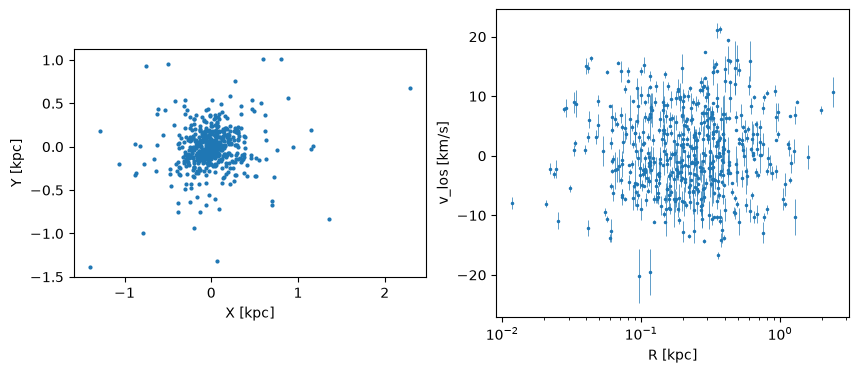

In [3]:
meta = kio.load_meta('draco_1')
rhalf = float(meta.rhalf_kpc.value); lrs = float(np.log10(rhalf))

SET, PROF = 'walker23', 'CuspIso'           # <- change these to look at another mock
obs = load_mock(SETS[SET], PROF, meta)       # dict of float32 arrays: X, Y [kpc], v, err [km/s]
params = pd.read_csv(MOCKS / SETS[SET] / 'mock_catalog_params.csv')
truth = truth_labels(params[params.profile == PROF].iloc[0], rhalf)
tr150 = float(log_rho_150(truth[None], lrs)[0])

print(f'{len(obs["v"])} stars | r_half = {rhalf} kpc | median sigma_v = {np.median(obs["err"]):.2f} km/s')
print('truth (label space):', dict(zip(LABELS, truth.round(3))))
print(f'true log10 rho(150 pc) = {tr150:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(obs['X'], obs['Y'], s=4); ax[0].set_aspect('equal'); ax[0].set_xlabel('X [kpc]'); ax[0].set_ylabel('Y [kpc]')
ax[1].errorbar(np.hypot(obs['X'], obs['Y']), obs['v'], obs['err'], fmt='.', ms=3, lw=.5)
ax[1].set_xscale('log'); ax[1].set_xlabel('R [kpc]'); ax[1].set_ylabel('v_los [km/s]'); plt.show()

## 2. The galaxy log-likelihood

Eight parameters: the seven labels and the systemic velocity $v_{\rm sys}$.
For each parameter vector, every star gets the same $\theta$
(`repeat_interleave`), the observed velocities are shifted by $v_{\rm sys}$,
and the per-star $\log p$ are summed. The same function serves both models:
the joint one reads `pos` as part of its target, the velocity-only one as
context. Several parameter vectors are evaluated in one batch, which is what
makes the GPU sampler below fast.

In [4]:
X, Y, v = (torch.tensor(obs[k], device=dev) for k in ('X', 'Y', 'v'))
err = torch.tensor(obs['err'], device=dev).view(-1, 1)
n = len(v)


def log_like(model, theta):
    """Galaxy log-likelihood for each row of theta (shape (k, 8)); returns (k,)."""
    t = torch.tensor(np.atleast_2d(theta), dtype=torch.float32, device=dev)
    nw = len(t)
    b = StarBatch(pos=torch.stack([X, Y], 1).repeat(nw, 1),
                  vel=(v.repeat(nw) - t[:, 7].repeat_interleave(n)).view(-1, 1),
                  vel_error=err.repeat(nw, 1),
                  theta=t[:, :7].repeat_interleave(n, 0),
                  cond=torch.full((nw * n, 1), lrs, device=dev))
    with torch.no_grad():
        lp = model.log_prob(b).view(nw, n)
    lp = torch.where(torch.isfinite(lp), lp, torch.full_like(lp, -1e30))
    return lp.sum(1).cpu().numpy()


theta_true = np.append(truth, 0.0)           # v_sys = 0: the mock is in Draco's rest frame after the loader
print('log L at the truth:  velocity-only %.1f   joint %.1f' % (log_like(los, theta_true)[0], log_like(joint, theta_true)[0]))
print('(the difference is sum_i log p(x_i, y_i | r_half) plus the log vel_scale Jacobian: a constant in theta if the joint model is exact)')

log L at the truth:  velocity-only 985.5   joint 4457.1
(the difference is sum_i log p(x_i, y_i | r_half) plus the log vel_scale Jacobian: a constant in theta if the joint model is exact)


## 3. A one-dimensional scan

Vary one label with the others held at the truth. Up to a vertical shift the
two curves should coincide; a difference in **shape** is $\theta$ leaking
into the learned position factor.

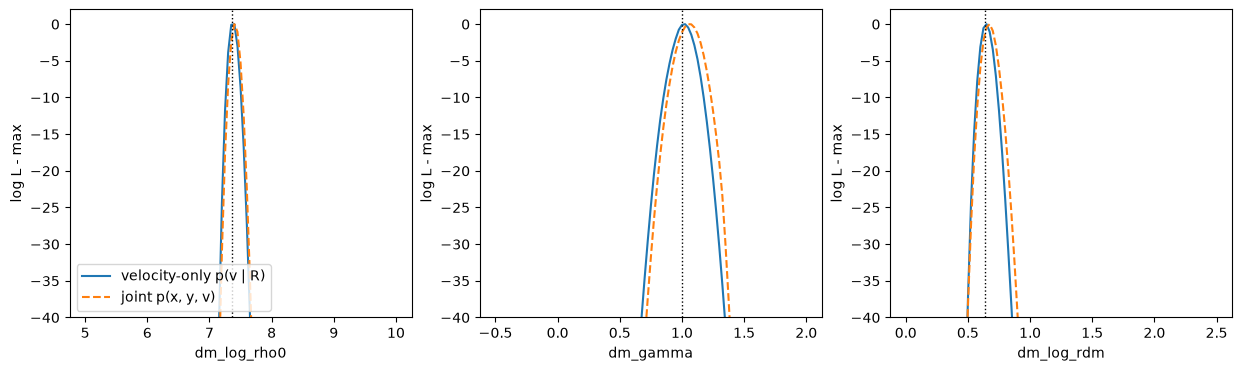

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ('dm_log_rho0', 'dm_gamma', 'dm_log_rdm')):
    k = LABELS.index(name)
    grid = np.linspace(PRIOR_MIN[k], PRIOR_MAX[k], 101)
    scan = np.tile(theta_true, (101, 1)); scan[:, k] = grid
    for model, lab, st in ((los, 'velocity-only p(v | R)', '-'), (joint, 'joint p(x, y, v)', '--')):
        ll = log_like(model, scan); ax.plot(grid, ll - ll.max(), st, label=lab)
    ax.axvline(truth[k], color='k', ls=':', lw=1); ax.set_ylim(-40, 2); ax.set_xlabel(name); ax.set_ylabel('log L - max')
axes[0].legend(); plt.show()

## 4. Sampling the two posteriors

`emcee` over the eight parameters with the 8p_v4 box prior; all walkers are
evaluated in one GPU batch (`vectorize=True`). Differential-evolution moves
as in the T2 run. 48 walkers × 1000 steps is enough to see the posterior
here; the batch script uses 64 × 4000.

In [6]:
import emcee


def sample(model, n_walkers=48, n_steps=1000, seed=0):
    def log_post(th):
        out = np.full(len(th), -np.inf)
        ok = np.all((th >= PRIOR_MIN) & (th <= PRIOR_MAX), axis=1)   # flat box prior
        if ok.any():
            out[ok] = log_like(model, th[ok])
        return out
    rng = np.random.default_rng(seed)
    p0 = rng.uniform(PRIOR_MIN, PRIOR_MAX, (n_walkers, 8))
    p0[:, 7] = np.median(obs['v']) + rng.normal(0, 1, n_walkers)
    s = emcee.EnsembleSampler(n_walkers, 8, log_post, vectorize=True,
                              moves=[(emcee.moves.DEMove(), .8), (emcee.moves.DESnookerMove(), .2)])
    s.run_mcmc(p0, n_steps, progress=False)
    return s.get_chain(discard=n_steps // 2, flat=True)


chains = {'velocity-only': sample(los), 'joint': sample(joint)}
for name, c in chains.items():
    lo_, med, hi = np.percentile(log_rho_150(c[:, :7], lrs), [16, 50, 84]); hw = (hi - lo_) / 2
    print(f'{name:14s} log10 rho(150 pc) = {med:.3f} +- {hw:.3f}    z = {(med - tr150) / hw:+.2f}    (truth {tr150:.3f})')

velocity-only  log10 rho(150 pc) = 8.096 +- 0.039    z = +0.67    (truth 8.070)
joint          log10 rho(150 pc) = 8.138 +- 0.061    z = +1.13    (truth 8.070)


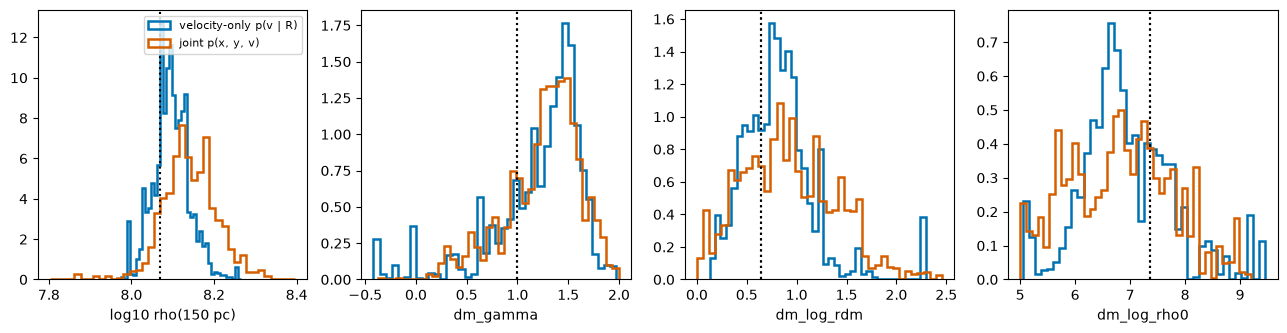

In [7]:
# marginals of log rho(150 pc) and of the three labels that set it
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for name, c, col in (('velocity-only p(v | R)', chains['velocity-only'], '#0072B2'), ('joint p(x, y, v)', chains['joint'], '#D55E00')):
    axes[0].hist(log_rho_150(c[:, :7], lrs), bins=40, histtype='step', lw=1.8, color=col, density=True, label=name)
    for ax, k in zip(axes[1:], (LABELS.index('dm_gamma'), LABELS.index('dm_log_rdm'), LABELS.index('dm_log_rho0'))):
        ax.hist(c[:, k], bins=40, histtype='step', lw=1.8, color=col, density=True); ax.set_xlabel(LABELS[k]); ax.axvline(truth[k], color='k', ls=':')
axes[0].axvline(tr150, color='k', ls=':'); axes[0].set_xlabel('log10 rho(150 pc)'); axes[0].legend(fontsize=8); plt.show()

## 5. The leak diagnostic

$$\Delta(\theta) \equiv \log\mathcal L_{\rm joint}(\theta) - \log\mathcal
L_{\rm los}(\theta) = \sum_i \log p(x_i, y_i \mid \theta, r_{1/2}).$$

For an exact position factor this is the same number at every $\theta$.
Evaluate it on samples of the velocity-only posterior: its standard
deviation is the size of the leak in nats at the galaxy level, and its
correlation with $\log\rho(150\,{\rm pc})$ says whether the leak pulls the
density posterior in a definite direction (it did, at the −0.5 level, for a
half-trained joint model).

leak: std 2.05 nats over the posterior; corr with log rho(150 pc) +0.34   (exact model: 0, 0)
per star that is 0.0040 nats, which is below what a per-star PIT test can see


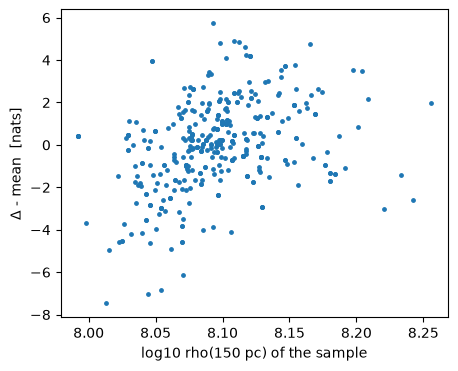

In [8]:
idx = np.random.default_rng(1).choice(len(chains['velocity-only']), 400, replace=False)
th = chains['velocity-only'][idx]
delta = log_like(joint, th) - log_like(los, th)
lr = log_rho_150(th[:, :7], lrs)
print(f'leak: std {delta.std():.2f} nats over the posterior; corr with log rho(150 pc) {np.corrcoef(delta, lr)[0, 1]:+.2f}   (exact model: 0, 0)')
print(f'per star that is {delta.std() / n:.4f} nats, which is below what a per-star PIT test can see')

plt.figure(figsize=(5, 4)); plt.scatter(lr, delta - delta.mean(), s=6)
plt.xlabel('log10 rho(150 pc) of the sample'); plt.ylabel('$\\Delta$ - mean  [nats]'); plt.show()

## 6. All twelve mocks

`diagnostics/mock_sf_compare.py` runs both models on every mock with
64 × 4000 steps and records the leak diagnostic; `diagnostics/plot_mock_sf.py`
makes the figures. Summary columns: `median` and `halfwidth` of
$\log_{10}\rho(150\,{\rm pc})$ per model (dex), `z` against the truth,
`hw_ratio` = joint half-width / velocity-only half-width, and the leak std and
correlation. The profile figures show the dark-matter density and slope
against 3-D radius, and $\sigma_{\rm los}$ and $\kappa_{\rm los}$ against
projected radius (curves: Jeans model at the median draw; points: bin-averaged
posterior predictive; black: error-deconvolved binned data; dashed black:
truth). The corner plots show the seven labels with radii in kpc.

What to look for: whether the joint model's $z$ or half-width differs
between the `walker23` and `noSF` sets in a way the velocity-only model's
does not; that would be the selection acting through the learned position
factor.

In [9]:
CH = OUT / 'mock_sf'
if (CH / 'mock_sf_compare.csv').exists():
    df = pd.read_csv(CH / 'mock_sf_compare.csv')
    wide = df.pivot_table(index=['set', 'mock'], columns='model', values=['median', 'halfwidth', 'z'])
    wide['hw_ratio'] = wide[('halfwidth', 'joint')] / wide[('halfwidth', 'los')]
    display(wide.round(3))
    if 'leak_std_nats' in df:
        display(df[df.model == 'joint'][['set', 'mock', 'n_stars', 'leak_std_nats', 'leak_corr_rho150']].round(2))
    for f in sorted((CH / 'figures').glob('profiles_*.png')):
        display(Image(str(f), width=1100))
    for f in sorted((CH / 'figures').glob('corner_*.png')):
        display(Image(str(f), width=900))
else:
    print('batch run not finished yet; see ~/scratch/local_logs/nle/mock_sf_compare.log')

batch run not finished yet; see ~/scratch/local_logs/nle/mock_sf_compare.log
